# Phase 3: Bearing fault pipeline (CWRU)
Run the cells top to bottom (Runtime > Run all). Needs internet (Colab has it).

In [1]:
!git clone https://github.com/anewsha08/edge-fault-genai.git
%cd edge-fault-genai
!pip install -q scipy scikit-learn matplotlib

Cloning into 'edge-fault-genai'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 24 (delta 2), reused 23 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 14.12 KiB | 850.00 KiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/edge-fault-genai


## 1. Download CWRU, cut windows, extract features (~40 files, a few minutes)

In [2]:
!python ml/prepare_data.py

[1/40] file 97 normal size=0.0 load=0
  downloading https://engineering.case.edu/sites/default/files/97.mat
[2/40] file 98 normal size=0.0 load=1
  downloading https://engineering.case.edu/sites/default/files/98.mat
[3/40] file 99 normal size=0.0 load=2
  downloading https://engineering.case.edu/sites/default/files/99.mat
[4/40] file 100 normal size=0.0 load=3
  downloading https://engineering.case.edu/sites/default/files/100.mat
[5/40] file 105 inner size=0.007 load=0
  downloading https://engineering.case.edu/sites/default/files/105.mat
[6/40] file 106 inner size=0.007 load=1
  downloading https://engineering.case.edu/sites/default/files/106.mat
[7/40] file 107 inner size=0.007 load=2
  downloading https://engineering.case.edu/sites/default/files/107.mat
[8/40] file 108 inner size=0.007 load=3
  downloading https://engineering.case.edu/sites/default/files/108.mat
[9/40] file 169 inner size=0.014 load=0
  downloading https://engineering.case.edu/sites/default/files/169.mat
[10/40] fil

## 2. Train. Split by motor load (train 0-1 HP, val 2 HP, test 3 HP) = honest estimate

In [3]:
!python ml/train.py --split load

split=load: train=5679 val=3072 test=3081
RandomForest test acc: 0.985
I0000 00:00:1791828109.237235    1823 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791828109.352307    1823 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791828112.330814    1823 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1791828113.173283    1823 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
MLP float test acc: 0.974  (1364 params)


## 3. Same data with a random window split. Expect a higher, inflated number. Write this contrast in your README.

In [4]:
!python ml/train.py --split random --out ml/out_random

split=random: train=8282 val=1775 test=1775
RandomForest test acc: 0.999
I0000 00:00:1791828147.706710    3002 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791828147.773574    3002 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791828150.597675    3002 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1791828151.421447    3002 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
MLP float test acc: 1.000  (1364 params)


## 4. Quantize to int8 and export the C array for the MCU
Re-run the load split first so `ml/out` holds that model.

In [5]:
!python ml/train.py --split load
!python ml/quantize_export.py

split=load: train=5679 val=3072 test=3081
RandomForest test acc: 0.985
I0000 00:00:1791828186.152577    4157 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791828186.219306    4157 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791828188.875622    4157 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1791828189.709514    4157 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
MLP float test acc: 0.974  (1364 params)
I0000 00:00:1791828215.947101    5292 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791828216.022325    5292 cpu_feature_guard.cc:227] This Tenso

## 5. Look at results

{'split': 'load', 'n_train': 5679, 'n_val': 3072, 'n_test': 3081, 'random_forest_test_acc': 0.98539435248296, 'mlp_float_test_acc': 0.9740344044141512, 'mlp_params': 1364}
{'float_test_acc': 0.9740344044141512, 'int8_test_acc': 0.9740344044141512, 'accuracy_drop': 0.0, 'tflite_size_bytes': 5272, 'float_model_params': 1364, 'input_scale': 0.032798394560813904, 'input_zero_point': -15, 'note': 'Flash size is the .tflite size; RAM/latency must be measured on the MCU (Phase 3 firmware).'}


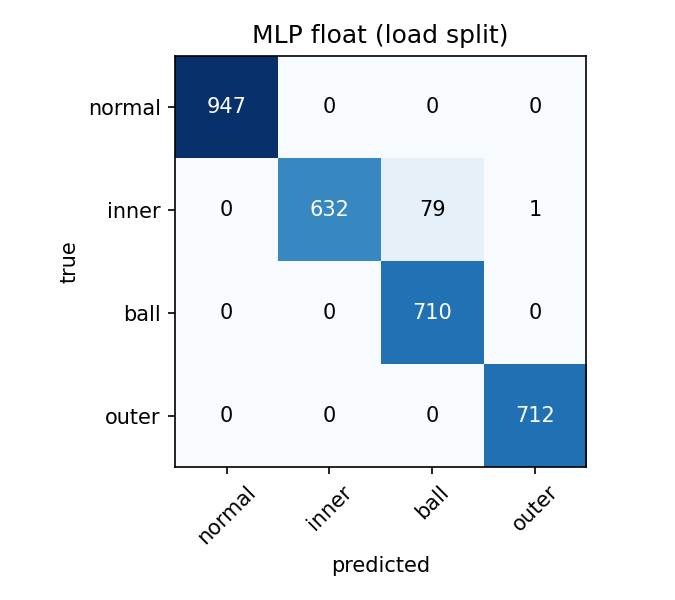

In [6]:
import json
from IPython.display import Image, display
print(json.load(open('ml/out/metrics.json')))
print(json.load(open('ml/out/quant_report.json')))
display(Image('ml/out/cm_mlp_float.png'))

## 6. Download results
Download `ml/out/metrics.json`, `quant_report.json`, the confusion-matrix PNGs and `model_data.cc`, then copy them into your repo.

In [7]:
!zip -r ml_results.zip ml/out ml/out_random
from google.colab import files
files.download('ml_results.zip')

  adding: ml/out/ (stored 0%)
  adding: ml/out/metrics.json (deflated 33%)
  adding: ml/out/cm_rf.png (deflated 14%)
  adding: ml/out/cm_mlp_float.png (deflated 14%)
  adding: ml/out/quant_report.json (deflated 34%)
  adding: ml/out/model_int8.tflite (deflated 43%)
  adding: ml/out/scaler.json (deflated 58%)
  adding: ml/out/split_idx.npz (deflated 81%)
  adding: ml/out/model.keras (deflated 57%)
  adding: ml/out/model_data.cc (deflated 84%)
  adding: ml/out_random/ (stored 0%)
  adding: ml/out_random/metrics.json (deflated 34%)
  adding: ml/out_random/cm_rf.png (deflated 15%)
  adding: ml/out_random/cm_mlp_float.png (deflated 14%)
  adding: ml/out_random/scaler.json (deflated 58%)
  adding: ml/out_random/split_idx.npz (deflated 67%)
  adding: ml/out_random/model.keras (deflated 57%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>